# Côte d'Ivoire - Projet PROMIRE / ONU-REDD

2 · Estimations de superficie et incertitudes, national et par zone phytogéographique - estimateur stratifié (STR) SBAE, 2021-2025
-------
Ce notebook calcule, pour chaque classe d'activité (SNF, SF, SDegF, Deg, Def, Gain), la superficie estimée et son incertitude (erreur standard, incertitude et intervalle de confiance à 90 %) au niveau national et pour chacune des quatre zones phytogéographiques, puis compare la somme des zones à l'estimation nationale. Il suit l'estimateur stratifié (STR) de Cochran (1977) / Olofsson et al. (2014), utilisé dans l'ensemble des outils SBAE de la FAO.

**Entrées** : `results/CIV_echantillons_activite_2021_2025.csv` (produit par le notebook `1`) et les zones phytogéographiques (`data/ZnePhytoGeo_CI.shp`).

**Sorties** (dossier `results/`), classeurs Excel dynamiques produits par le module `sbae_excel.py` :

- `CIV_estimations_superficie_STR_2021_2025_par_zone.xlsx` : estimations nationales et par zone ;
- `CIV_estimations_superficie_STR_2021_2025_par_zone_PRE.xlsx` : mêmes estimations pour le seul territoire du PRE (Programme de Réductions des Émissions), dernière section.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [2]:
# Échantillons situés hors des zones phytogéographiques (en bordure du pays) :
# True = ils sont attribués à la zone la plus proche ; False = ils sont exclus
chercher_la_zone_la_plus_proche = True

## Chargement des zones phytogéographiques

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

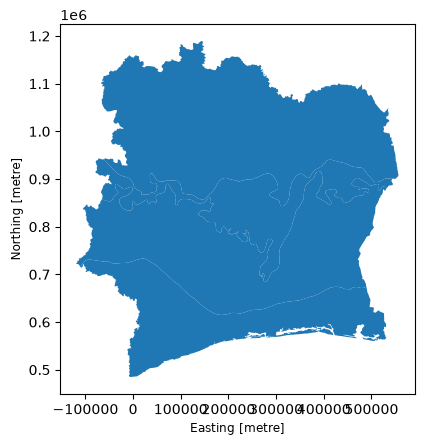

In [4]:
zones = gpd.read_file('data/ZnePhytoGeo_CI.shp')
zones.plot()

In [5]:
print(zones.Zone)

0       Secteur Ombrophile
1        Secteur Soudanais
2    Secteur Sub Soudanais
3        Secteur mésophile
Name: Zone, dtype: str


## Chargement des données

In [6]:
data_path = 'results/CIV_echantillons_activite_2021_2025.csv'   # sortie du notebook 1
df = pd.read_csv(data_path)
len(df)

12000

In [7]:
df.head()

,plotid,center_lon,center_lat,strata,pre,activity,n1_2021,n1_2022,n1_2023,n1_2024,n1_2025,n2_2021,n2_2022,n2_2023,n2_2024,n2_2025,n3_2021,n3_2025
0,1,-7.388,4.406,2.000,True,SNF,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Hevea,Hevea,Hevea,Hevea,Hevea,Hevea_Plein_Soleil,Hevea_Plein_Soleil
1,2,-7.502,4.417,2.000,True,SNF,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Hevea,Hevea,Hevea,Hevea,Hevea,Hevea_Associe_Arbres,Hevea_Associe_Arbres
2,3,-7.452,4.421,3.000,True,SNF,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Jachere_Fourree,Jachere_Fourree,Jachere_Fourree,Jachere_Fourree,Jachere_Fourree,NaN,NaN
3,4,-7.311,4.461,3.000,True,SF,Terres_Forestieres,Terres_Forestieres,Terres_Forestieres,Terres_Forestieres,Terres_Forestieres,Foret_Galerie,Foret_Galerie,Foret_Galerie,Foret_Galerie,Foret_Galerie,NaN,NaN
4,5,-7.440,4.472,2.000,True,SNF,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Terres_Cultivees,Palmier,Palmier,Palmier,Palmier,Palmier,NaN,NaN


### Contrôle qualité des données

In [8]:
doublon = df['plotid'].duplicated().any()
if doublon:
    print("Problème : plotid en double")
else:
    print("Tout est correct : plotid sont uniques")

Tout est correct : plotid sont uniques


In [9]:
missing_strata = df['strata'].isna().sum()
print(f"{missing_strata} échantillons n'ont pas de strate (hors du territoire ou zone masquée) et sont exclus de l'estimateur")

df_valid = df.dropna(subset=['strata']).copy()
df_valid['strata'] = df_valid['strata'].astype(int)
len(df_valid)

90 échantillons n'ont pas de strate (hors du territoire ou zone masquée) et sont exclus de l'estimateur


11910

In [10]:
count_values = df_valid['activity'].value_counts()
print(count_values)

activity
SNF      9633
SF       1310
SDegF     856
Def        84
Deg        17
Gain       10
Name: count, dtype: int64


## Attribution d'une zone phytogéographique à chaque échantillon

In [11]:
gdf = gpd.GeoDataFrame(df,geometry=gpd.points_from_xy(df.center_lon, df.center_lat),crs="EPSG:4326").to_crs('EPSG:32630')
gdf_w_zones = gpd.sjoin_nearest(gdf[['plotid','geometry']],zones,how='left', distance_col='zdistance')

<Axes: ylabel='Frequency'>

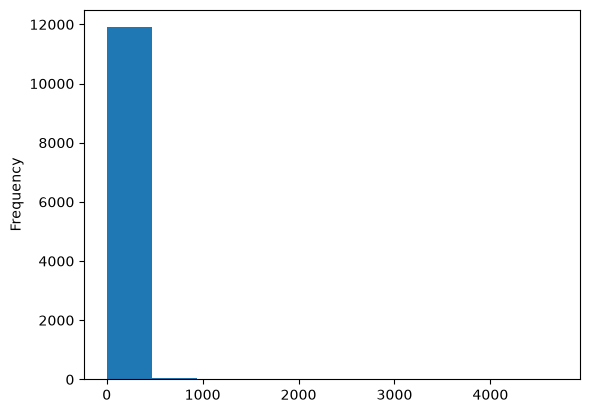

In [12]:
gdf_w_zones.zdistance.plot.hist()

In [13]:
print("Nombre d'échantillons hors des zones :", len(gdf_w_zones[gdf_w_zones.zdistance > 0]))
df_valid = df_valid.merge(gdf_w_zones[['plotid', 'Zone', 'zdistance']]
                          .rename(columns={'Zone': 'zone'}), on='plotid', how='left')
if chercher_la_zone_la_plus_proche:
    print('Ces échantillons sont attribués à la zone la plus proche')
else:
    df_valid = df_valid[df_valid.zdistance == 0]
    print('Ces échantillons sont exclus')

Nombre d'échantillons hors des zones : 178
Ces échantillons sont attribués à la zone la plus proche


In [14]:
print("Nombre d'échantillons avec strate :", len(df_valid))
df_valid['zone'].value_counts()

Nombre d'échantillons avec strate : 11910


zone
Secteur Soudanais        4571
Secteur mésophile        3575
Secteur Ombrophile       2393
Secteur Sub Soudanais    1371
Name: count, dtype: int64

In [15]:
df_valid['activity'].value_counts()

activity
SNF      9633
SF       1310
SDegF     856
Def        84
Deg        17
Gain       10
Name: count, dtype: int64

## Analyse rapide des données

### Nombre d'échantillons par classe d'activité

In [16]:
count_values = df_valid.groupby('zone')['activity'].value_counts().unstack('zone')
print(count_values)

zone      Secteur Ombrophile  Secteur Soudanais  Secteur Sub Soudanais  \
activity                                                                 
Def                   12.000             33.000                  9.000   
Deg                    4.000              5.000                  2.000   
Gain                     NaN                NaN                    NaN   
SDegF                267.000             85.000                 55.000   
SF                   439.000            636.000                124.000   
SNF                 1671.000           3812.000               1181.000   

zone      Secteur mésophile  
activity                     
Def                  30.000  
Deg                   6.000  
Gain                 10.000  
SDegF               449.000  
SF                  111.000  
SNF                2969.000  


### Exclusion des échantillons d'activité ND

L'activité `ND` est attribuée par le notebook `1` aux échantillons dont la classe de niveau 1 est manquante (ou `no_data`) en 2021 ou en 2025. Ils sont exclus de l'estimateur.

In [17]:
df_valid = df_valid[df_valid.activity!='ND']
len(df_valid)

11910

### Nombre d'échantillons par classe d'activité, par zone et par strate

In [18]:
count_values = (
    df_valid.groupby(['zone', 'strata'])['activity'].value_counts()
    .unstack(['zone', 'strata'], fill_value=0)
    .sort_index(axis=1)
)
print(count_values)

zone     Secteur Ombrophile           Secteur Soudanais            \
strata                    1    2    3                 1     2   3   
activity                                                            
Def                       3    3    6                 8    18   7   
Deg                       1    1    2                 2     3   0   
Gain                      0    0    0                 0     0   0   
SDegF                    95   78   94                36    42   7   
SF                       31  114  294               293   292  51   
SNF                     838  620  213              2713  1042  57   

zone     Secteur Sub Soudanais          Secteur mésophile             
strata                       1    2   3                 1     2    3  
activity                                                              
Def                          3    4   2                15     8    7  
Deg                          1    1   0                 1     4    1  
Gain                   

In [19]:
count_values = (
    df_valid.groupby(['zone', 'strata'])['activity'].value_counts(normalize=True)
    .unstack(['zone', 'strata'], fill_value=0)
    .sort_index(axis=1) * 100
)
print(count_values)

zone     Secteur Ombrophile               Secteur Soudanais                \
strata                    1      2      3                 1      2      3   
activity                                                                    
Def                   0.310  0.368  0.985             0.262  1.288  5.738   
Deg                   0.103  0.123  0.328             0.066  0.215  0.000   
Gain                  0.000  0.000  0.000             0.000  0.000  0.000   
SDegF                 9.814  9.559 15.435             1.180  3.006  5.738   
SF                    3.202 13.971 48.276             9.600 20.902 41.803   
SNF                  86.570 75.980 34.975            88.893 74.588 46.721   

zone     Secteur Sub Soudanais               Secteur mésophile                
strata                       1      2      3                 1      2      3  
activity                                                                      
Def                      0.392  0.805  1.852             0.792  0.634

Le tableau suivant donne $\hat{p}_{hk}\,(1-\hat{p}_{hk})$ pour chaque classe et chaque combinaison zone × strate : c'est le terme de variance qui entre dans l'erreur standard de l'estimateur (voir les équations plus bas). Il est maximal pour les classes proches de 50 % et très faible pour les classes rares.

In [20]:
(count_values/100) * (1 - (count_values/100))

zone     Secteur Ombrophile             Secteur Soudanais              \
strata                    1     2     3                 1     2     3   
activity                                                                
Def                   0.003 0.004 0.010             0.003 0.013 0.054   
Deg                   0.001 0.001 0.003             0.001 0.002 0.000   
Gain                  0.000 0.000 0.000             0.000 0.000 0.000   
SDegF                 0.089 0.086 0.131             0.012 0.029 0.054   
SF                    0.031 0.120 0.250             0.087 0.165 0.243   
SNF                   0.116 0.183 0.227             0.099 0.190 0.249   

zone     Secteur Sub Soudanais             Secteur mésophile              
strata                       1     2     3                 1     2     3  
activity                                                                  
Def                      0.004 0.008 0.018             0.008 0.006 0.016  
Deg                      0.001 0.002 0.000             0.001 0.003 0.002  
Gain                     0.000 0.000 0.000             0.002 0.004 0.005  
SDegF                    0.032 0.044 0.061             0.087 0.119 0.173  
SF                       0.055 0.108 0.139             0.019 0.031 0.077  
SNF                      0.087 0.147 0.188             0.109 0.150 0.221

## Estimateur de superficie stratifié (STR) — niveau national

Pour un plan d'échantillonnage stratifié à $H$ strates, la proportion de superficie de la classe $k$ est la moyenne des proportions d'échantillon de chaque strate, pondérée par la superficie des strates :

$$
\hat{p}_k \;=\; \sum_{h=1}^{H} W_h\,\hat{p}_{hk},
\qquad
\hat{p}_{hk} \;=\; \frac{n_{hk}}{n_h},
\qquad
W_h \;=\; \frac{A_h}{A}
$$

$$
\widehat{\mathrm{SE}}(\hat{p}_k) \;=\; \sqrt{\;\sum_{h=1}^{H} W_h^{2}\;\frac{\hat{p}_{hk}\,\left(1-\hat{p}_{hk}\right)}{n_h-1}\;}
$$

La superficie, son erreur standard, l'incertitude $U$ (à 90 %) et l'intervalle de confiance s'en déduisent :

$$
\hat{A}_k \;=\; A\,\hat{p}_k,
\qquad
\widehat{\mathrm{SE}}(\hat{A}_k) \;=\; A\;\widehat{\mathrm{SE}}(\hat{p}_k),
\qquad
U(\hat{A}_k) \;=\; 1{,}645\;\widehat{\mathrm{SE}}(\hat{A}_k),
\qquad
\mathrm{IC}_{90\%}(\hat{A}_k) \;=\; \hat{A}_k \,\pm\, U(\hat{A}_k)
$$

| Symbole | Signification |
|:--|:--|
| $A_h$ | superficie cartographiée de la strate $h$ |
| $A = \sum_h A_h$ | superficie cartographiée totale |
| $W_h$ | poids en superficie de la strate $h$ |
| $n_h$ | nombre d'échantillons dans la strate $h$ |
| $n_{hk}$ | nombre d'échantillons de la strate $h$ attribués à la classe $k$ par les données de référence (CEO) |
| $U$ | incertitude : $z \cdot \widehat{\mathrm{SE}}$, avec $z = 1{,}645$ pour 90 % |

Référence : Olofsson, P. et al. (2014) *Good practices for estimating area and assessing accuracy of land change*, Remote Sensing of Environment 148.

### Estimation par zone — post-stratification zone × strate

Les zones phytogéographiques ne sont pas des strates du plan d'échantillonnage : elles recoupent les strates. La superficie cartographiée de chaque strate $h$ dans chaque zone $z$, $A_{hz}$, est connue, et les échantillons de la strate $h$ tombant dans la zone $z$ constituent un échantillon aléatoire de la cellule $(h, z)$. Chaque zone est donc traitée comme une population stratifiée à part entière, avec ses propres poids :

$$
W_{hz} \;=\; \frac{A_{hz}}{A_z},
\qquad
A_z \;=\; \sum_{h=1}^{H} A_{hz}
$$

$$
\hat{p}_{kz} \;=\; \sum_{h=1}^{H} W_{hz}\,\hat{p}_{hkz},
\qquad
\hat{p}_{hkz} \;=\; \frac{n_{hkz}}{n_{hz}}
$$

$$
\widehat{\mathrm{SE}}(\hat{p}_{kz}) \;=\; \sqrt{\;\sum_{h=1}^{H} W_{hz}^{2}\;\frac{\hat{p}_{hkz}\,\left(1-\hat{p}_{hkz}\right)}{n_{hz}-1}\;}
$$

$$
\hat{A}_{kz} \;=\; A_z\,\hat{p}_{kz},
\qquad
\widehat{\mathrm{SE}}(\hat{A}_{kz}) \;=\; A_z\;\widehat{\mathrm{SE}}(\hat{p}_{kz}),
\qquad
\sum_k \hat{A}_{kz} \;=\; A_z
$$

| Symbole | Signification |
|:--|:--|
| $A_{hz}$ | superficie cartographiée de la strate $h$ dans la zone $z$ |
| $A_z$ | superficie cartographiée de la zone $z$ |
| $n_{hz}$ | nombre d'échantillons de la strate $h$ situés dans la zone $z$ |
| $n_{hkz}$ | nombre de ces échantillons attribués à la classe $k$ |

La somme des classes d'une zone est égale à sa superficie cartographiée, et la variance due au nombre aléatoire d'échantillons tombant dans chaque zone est éliminée.

### Superficies des strates (poids Wh)

In [21]:
strata_sizes = (
    df_valid['strata'].value_counts()
    .rename_axis('stratum')
    .reset_index(name='n_h')
)
# Superficie cartographiée de chaque strate (ha), attribuée par numéro de strate
strata_sizes['area_ha'] = strata_sizes['stratum'].map({1: 19080547.4, 2: 10923787.62, 3: 2037564.502})
strata_sizes

,stratum,n_h,area_ha
0,1,6680,19080547.400
1,2,3972,10923787.620
2,3,1258,2037564.502


In [22]:
total_area_ha = strata_sizes['area_ha'].sum()
print('Superficie totale (ha) :',total_area_ha)
Wh = strata_sizes.set_index('stratum')['area_ha'] / total_area_ha
Wh

Superficie totale (ha) : 32041899.521999996


stratum
1   0.595
2   0.341
3   0.064
Name: area_ha, dtype: float64

In [23]:
print("Nombre d'échantillons par zone et par strate :")
pd.crosstab(df_valid['zone'], df_valid['strata'], margins=True)

Nombre d'échantillons par zone et par strate :


strata,1,2,3,All
zone,,,,
Secteur Ombrophile,968,816,609,2393
Secteur Soudanais,3052,1397,122,4571
Secteur Sub Soudanais,766,497,108,1371
Secteur mésophile,1894,1262,419,3575
All,6680,3972,1258,11910


### Superficies des strates par zone (poids W<sub>hz</sub>)

In [24]:
# Superficie cartographiée de chaque strate dans chaque zone (km², convertie en ha)
# script gee: https://code.earthengine.google.com/6d246c730ae5efc836ced21ef90d74ac


area_hz_km2 = pd.DataFrame({
    'Secteur Ombrophile':    [28127.4082,	21377.56608,	8586.479557],
    'Secteur Soudanais':     [86493.21318,	39087.48208,	2729.667459],
    'Secteur Sub Soudanais': [21759.34011,	13883.2849,	1990.485385],
    'Secteur mésophile':     [54425.51251,	34889.54318,	7069.012614],
}, index=pd.Index([1, 2, 3], name='stratum')).T
area_hz_km2.index.name = 'zone'
area_hz = area_hz_km2 * 100
area_hz['total'] = area_hz.sum(axis=1)
area_hz

stratum,1,2,3,total
zone,,,,
Secteur Ombrophile,2812740.820,2137756.608,858647.956,5809145.384
Secteur Soudanais,8649321.318,3908748.208,272966.746,12831036.272
Secteur Sub Soudanais,2175934.011,1388328.490,199048.538,3763311.039
Secteur mésophile,5442551.251,3488954.318,706901.261,9638406.830


In [25]:
# Contrôle : somme des zones par strate vs superficies nationales des strates
chk_strata = pd.DataFrame({
    'somme_zones_ha': area_hz[[1, 2, 3]].sum(),
    'national_ha': strata_sizes.set_index('stratum')['area_ha'],
})
chk_strata['diff_pct'] = (chk_strata['somme_zones_ha'] / chk_strata['national_ha'] - 1) * 100
print(chk_strata, '\n')
print(f"Superficie totale des zones : {area_hz['total'].sum():,.1f} ha vs {total_area_ha:,.1f} ha au niveau national")

Wh_zone = area_hz[[1, 2, 3]].div(area_hz['total'], axis=0)
Wh_zone

         somme_zones_ha  national_ha  diff_pct
stratum                                       
1          19080547.400 19080547.400     0.000
2          10923787.624 10923787.620     0.000
3           2037564.502  2037564.502    -0.000 

Superficie totale des zones : 32,041,899.5 ha vs 32,041,899.5 ha au niveau national


stratum,1,2,3
zone,,,
Secteur Ombrophile,0.484,0.368,0.148
Secteur Soudanais,0.674,0.305,0.021
Secteur Sub Soudanais,0.578,0.369,0.053
Secteur mésophile,0.565,0.362,0.073


### Calcul des estimations stratifiées par classe d'activité et par zone

In [34]:
def stratified_area_estimate(df, class_col, stratum_col, weights, total_area_ha, z=1.645, verbose=False):
    """Estimateur de superficie STR (échantillonnage aléatoire stratifié) -- Cochran (1977) / Olofsson et al. (2014).
    `weights` est une Series pandas indexée par valeur de strate, contenant Wh = area_h / total_area."""
    n_h = df.groupby(stratum_col).size()
    rows = []
    for cls in sorted(df[class_col].dropna().unique()):
        n_hk = (
            df[df[class_col] == cls]
            .groupby(stratum_col).size()
            .reindex(n_h.index, fill_value=0)
        )
        p_h = n_hk / n_h
        w_h = weights.reindex(n_h.index)
        p_hat = (w_h * p_h).sum()
        var_terms = w_h**2 * p_h * (1 - p_h) / (n_h - 1)
        var_hat = var_terms.replace([np.inf, -np.inf], np.nan).sum()
        se_hat = np.sqrt(var_hat)
        area = p_hat * total_area_ha
        se_area = se_hat * total_area_ha
        if verbose:
            print (cls, var_terms * area)
        rows.append({
            'activity': cls,
            'n_sample': int((df[class_col] == cls).sum()),
            'proportion': p_hat,
            'area_ha': area,
            'se_ha': se_area,
            'ci90_ha': z * se_area,
            'ci90_pct_of_area': (z * se_area / area * 100) if area else np.nan,
        })
            
    return pd.DataFrame(rows).sort_values('area_ha', ascending=False).reset_index(drop=True)

results = stratified_area_estimate(df_valid, 'activity', 'strata', Wh, total_area_ha, verbose=False)
results

,activity,n_sample,proportion,area_ha,se_ha,ci90_ha,ci90_pct_of_area
0,SNF,9633,0.824,26404585.505,107665.687,177110.055,0.671
1,SF,1310,0.100,3195815.004,84645.777,139242.302,4.357
2,SDegF,856,0.067,2162822.515,72586.553,119404.879,5.521
3,Def,84,0.007,209224.339,23236.866,38224.644,18.270
4,Deg,17,0.001,43892.688,10796.416,17760.104,40.463
5,Gain,10,0.001,25559.471,8215.331,13514.219,52.874


In [35]:
def stratified_area_estimate_by_zone(df, class_col, stratum_col, zone_col, area_hz, z=1.645):
    """Post-stratification zone x strate : l'estimateur STR est appliqué séparément à chaque zone,
    avec ses propres poids W_hz = A_hz / A_z et les échantillons de la zone uniquement.
    `area_hz` est un DataFrame indexé par zone, avec une colonne par strate (superficies en ha)."""
    out = []
    for zn in sorted(df[zone_col].dropna().unique()):
        a_h = area_hz.loc[zn, [1, 2, 3]]
        res = stratified_area_estimate(df[df[zone_col] == zn], class_col, stratum_col, a_h / a_h.sum(), a_h.sum(), z=z)
        res.insert(0, 'zone', zn)
        out.append(res)
    return pd.concat(out, ignore_index=True)


results_zone = stratified_area_estimate_by_zone(df_valid, 'activity', 'strata', 'zone', area_hz)
results_zone['pct_of_zone'] = results_zone['area_ha'] / results_zone.groupby('zone')['area_ha'].transform('sum') * 100
results_zone

,zone,activity,n_sample,proportion,area_ha,se_ha,ci90_ha,ci90_pct_of_area,pct_of_zone
0,Secteur Ombrophile,SNF,1671,0.750,4359587.851,47437.673,78034.972,1.790,75.047
1,Secteur Ombrophile,SF,439,0.138,803254.320,35076.415,57700.702,7.183,13.827
2,Secteur Ombrophile,SDegF,267,0.106,612921.671,36975.390,60824.516,9.924,10.551
3,Secteur Ombrophile,Def,12,0.004,25036.157,7592.508,12489.676,49.887,0.431
4,Secteur Ombrophile,Deg,4,0.001,8345.386,4390.428,7222.253,86.542,0.144
5,Secteur Soudanais,SNF,3812,0.836,10731607.041,68181.606,112158.741,1.045,83.638
6,Secteur Soudanais,SF,636,0.137,1761470.488,63931.567,105167.428,5.970,13.728
7,Secteur Soudanais,SDegF,85,0.018,235199.738,25263.896,41559.109,17.670,1.833
8,Secteur Soudanais,Def,33,0.007,88697.159,15382.058,25303.485,28.528,0.691
9,Secteur Soudanais,Deg,5,0.001,14061.845,6285.678,10339.940,73.532,0.110


In [36]:
print("Superficie estimée par classe et par zone (ha) :")
results_zone.pivot(index='activity', columns='zone', values='area_ha').fillna(0)

Superficie estimée par classe et par zone (ha) :


zone,Secteur Ombrophile,Secteur Soudanais,Secteur Sub Soudanais,Secteur mésophile
activity,,,,
Def,25036.157,88697.159,23381.689,77030.417
Deg,8345.386,14061.845,5634.062,15619.183
Gain,0.000,0.000,0.000,25818.071
SDegF,612921.671,235199.738,148166.019,1160936.796
SF,803254.320,1761470.488,331402.245,273082.658
SNF,4359587.851,10731607.041,3254727.024,8085919.705


In [37]:
print("Incertitude relative à 90 % (en % de la superficie estimée) :")
results_zone.pivot(index='activity', columns='zone', values='ci90_pct_of_area')

Incertitude relative à 90 % (en % de la superficie estimée) :


zone,Secteur Ombrophile,Secteur Soudanais,Secteur Sub Soudanais,Secteur mésophile
activity,,,,
Def,49.887,28.528,55.352,30.456
Deg,86.542,73.532,116.323,67.932
Gain,NaN,NaN,NaN,52.741
SDegF,9.924,17.670,21.907,7.381
SF,7.183,5.970,14.145,15.703
SNF,1.790,1.045,1.737,1.190


### Contrôles de cohérence

In [38]:
# Contrôles de cohérence
# 1. Avec la post-stratification, la somme des classes d'une zone est égale à sa superficie cartographiée
print((results_zone.groupby('zone')['area_ha'].sum() - area_hz['total']).rename('diff_ha').to_string(), '\n')

# 2. Combinaisons zone/classe avec peu d'échantillons
low_sample = results_zone[results_zone['n_sample'] < 10]
if len(low_sample):
    print("Combinaisons zone/classe comptant moins de 10 échantillons -- interpréter leur SE/incertitude avec prudence :")
    print(low_sample[['zone', 'activity', 'n_sample']].to_string(index=False))

zone
Secteur Ombrophile      0.000
Secteur Soudanais       0.000
Secteur Sub Soudanais   0.000
Secteur mésophile       0.000 

Combinaisons zone/classe comptant moins de 10 échantillons -- interpréter leur SE/incertitude avec prudence :
                 zone activity  n_sample
   Secteur Ombrophile      Deg         4
    Secteur Soudanais      Deg         5
Secteur Sub Soudanais      Def         9
Secteur Sub Soudanais      Deg         2
    Secteur mésophile      Deg         6


### Visualisation des estimations de superficie par zone avec leur incertitude à 90 %

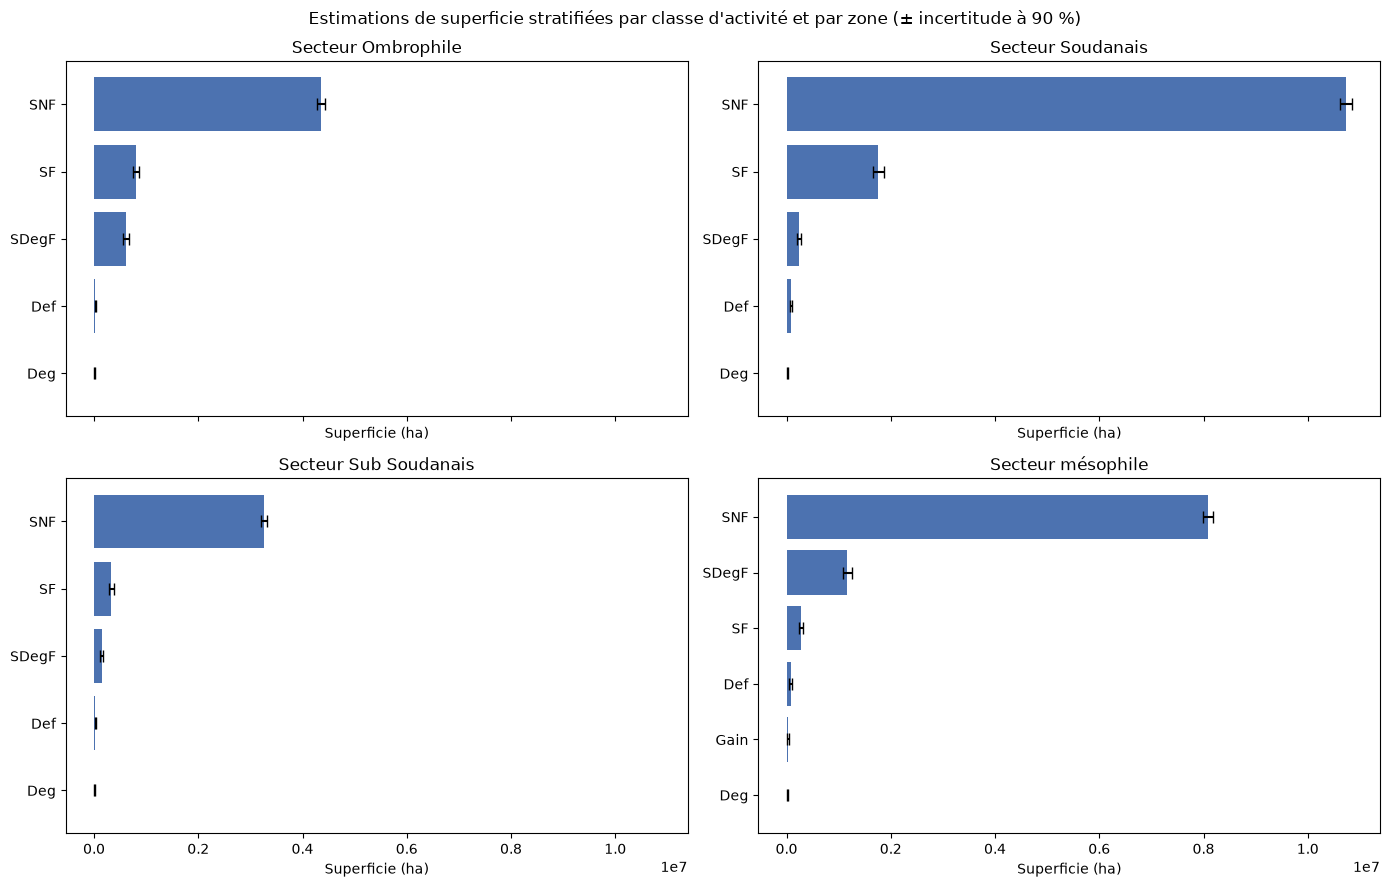

In [39]:
zone_list = sorted(results_zone['zone'].unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, zn in zip(axes.flat, zone_list):
    order = results_zone[results_zone['zone'] == zn].sort_values('area_ha', ascending=True)
    ax.barh(order['activity'], order['area_ha'], xerr=order['ci90_ha'], capsize=4, color='#4C72B0')
    ax.set_title(zn)
    ax.set_xlabel('Superficie (ha)')
fig.suptitle("Estimations de superficie stratifiées par classe d'activité et par zone (± incertitude à 90 %)")
plt.tight_layout()
plt.show()

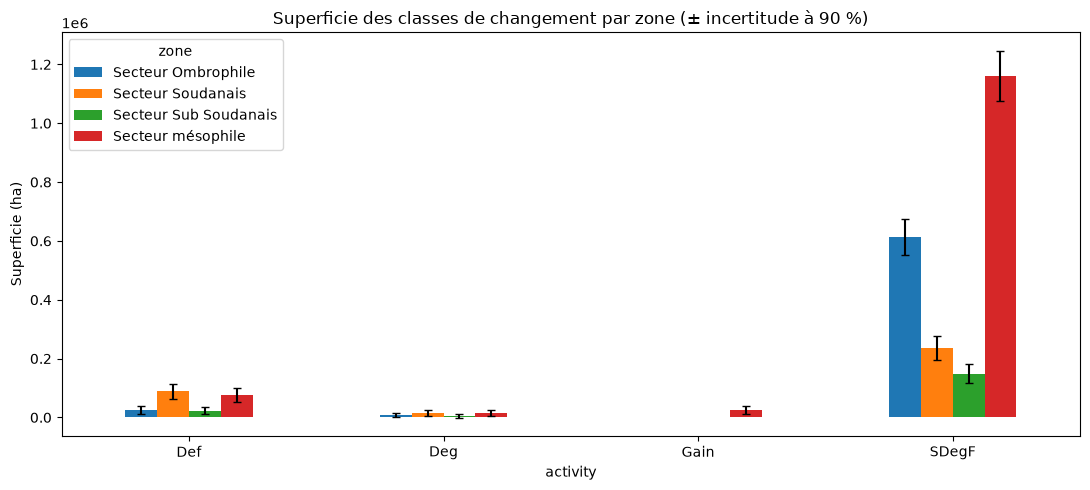

In [40]:
# Classes de changement uniquement (sans SNF/SF), pour une meilleure lisibilité
chg = results_zone[~results_zone['activity'].isin(['SNF', 'SF'])]
area_p = chg.pivot(index='activity', columns='zone', values='area_ha')
ci_p = chg.pivot(index='activity', columns='zone', values='ci90_ha')
ax = area_p.plot.bar(yerr=ci_p, capsize=3, figsize=(11, 5))
ax.set_ylabel('Superficie (ha)')
ax.set_title('Superficie des classes de changement par zone (± incertitude à 90 %)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Comparaison : SBAE national vs SBAE par zone

Les zones sont estimées à partir d'ensembles d'échantillons disjoints : les estimations par zone s'additionnent, et leurs variances aussi. Pour chaque classe $k$ :

$$
\hat{A}_k^{\,\Sigma z} \;=\; \sum_{z} \hat{A}_{kz},
\qquad
\widehat{\mathrm{SE}}\big(\hat{A}_k^{\,\Sigma z}\big) \;=\; \sqrt{\;\sum_{z} \widehat{\mathrm{SE}}(\hat{A}_{kz})^{2}\;}
$$

Cette somme des zones est comparée à l'estimation nationale $\hat{A}_k$ :

$$
\Delta_k \;=\; \hat{A}_k^{\,\Sigma z} - \hat{A}_k,
\qquad
\Delta_k\,(\%) \;=\; 100\,\frac{\Delta_k}{\hat{A}_k},
\qquad
\rho_k \;=\; \frac{\widehat{\mathrm{SE}}\big(\hat{A}_k^{\,\Sigma z}\big)}{\widehat{\mathrm{SE}}(\hat{A}_k)}
$$

Les deux estimations ne coïncident pas exactement : les estimateurs diffèrent (post-strates zone × strate vs strates seules) et la superficie totale des zones $\sum_z A_z$ est légèrement inférieure à la superficie nationale des strates $A$ (voir le contrôle des superficies plus haut). $\rho_k < 1$ indique que la post-stratification par zone réduit l'incertitude.

In [41]:
Z90 = 1.645

# Agrégation des SBAE par zone : somme des superficies, somme des variances
agg_zones = (results_zone.assign(var_ha=results_zone['se_ha'] ** 2)
             .groupby('activity')
             .agg(area_ha=('area_ha', 'sum'), var_ha=('var_ha', 'sum')))
agg_zones['se_ha'] = np.sqrt(agg_zones.pop('var_ha'))

cmp_nat = (results.set_index('activity')[['n_sample', 'area_ha', 'se_ha']]
           .join(agg_zones, lsuffix='_nat', rsuffix='_zones'))
for s in ['nat', 'zones']:
    cmp_nat[f'ci90_ha_{s}'] = Z90 * cmp_nat[f'se_ha_{s}']
    cmp_nat[f'ci90_pct_{s}'] = cmp_nat[f'ci90_ha_{s}'] / cmp_nat[f'area_ha_{s}'] * 100
cmp_nat['diff_ha'] = cmp_nat['area_ha_zones'] - cmp_nat['area_ha_nat']
cmp_nat['diff_pct'] = cmp_nat['diff_ha'] / cmp_nat['area_ha_nat'] * 100
cmp_nat['ratio_se'] = cmp_nat['se_ha_zones'] / cmp_nat['se_ha_nat']
cmp_nat = cmp_nat[['n_sample',
                   'area_ha_nat', 'se_ha_nat', 'ci90_ha_nat', 'ci90_pct_nat',
                   'area_ha_zones', 'se_ha_zones', 'ci90_ha_zones', 'ci90_pct_zones',
                   'diff_ha', 'diff_pct', 'ratio_se']].sort_values('area_ha_nat', ascending=False)

print(f"Superficie totale : nationale {total_area_ha:,.1f} ha ; somme des zones {area_hz['total'].sum():,.1f} ha "
      f"({(area_hz['total'].sum() / total_area_ha - 1) * 100:+.3f} %)")
cmp_nat

Superficie totale : nationale 32,041,899.5 ha ; somme des zones 32,041,899.5 ha (+0.000 %)


,n_sample,area_ha_nat,se_ha_nat,ci90_ha_nat,ci90_pct_nat,area_ha_zones,se_ha_zones,ci90_ha_zones,ci90_pct_zones,diff_ha,diff_pct,ratio_se
activity,,,,,,,,,,,,
SNF,9633,26404585.505,107665.687,177110.055,0.671,26431841.621,107240.524,176410.662,0.667,27256.116,0.103,0.996
SF,1310,3195815.004,84645.777,139242.302,4.357,3169209.710,82518.089,135742.257,4.283,-26605.294,-0.833,0.975
SDegF,856,2162822.515,72586.553,119404.879,5.521,2157224.225,71469.316,117567.025,5.450,-5598.290,-0.259,0.985
Def,84,209224.339,23236.866,38224.644,18.270,214145.423,23654.643,38911.887,18.171,4921.084,2.352,1.018
Deg,17,43892.688,10796.416,17760.104,40.463,43660.476,10782.470,17737.163,40.625,-232.212,-0.529,0.999
Gain,10,25559.471,8215.331,13514.219,52.874,25818.071,8277.663,13616.756,52.741,258.600,1.012,1.008


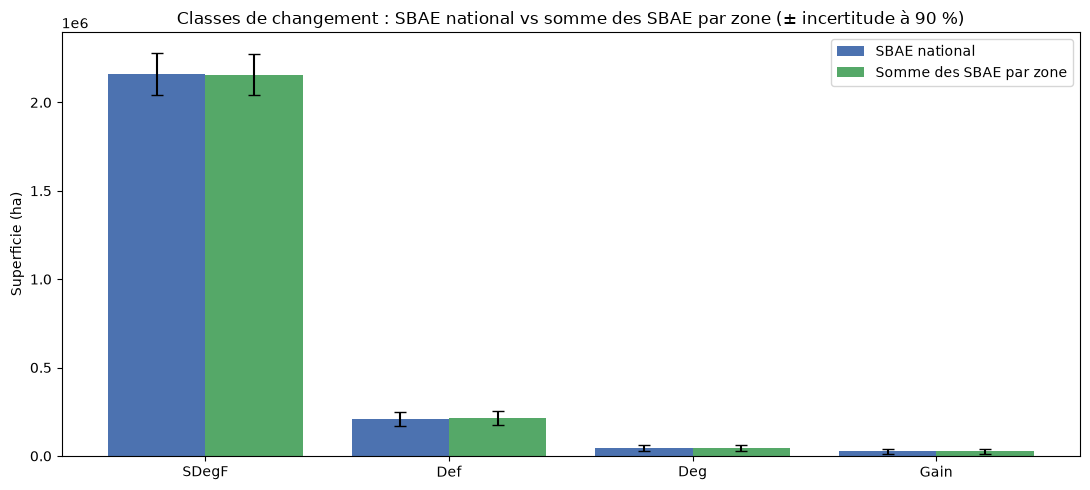

In [42]:
# Classes de changement : SBAE national vs somme des SBAE par zone (± incertitude à 90 %)
chg_cmp = cmp_nat.drop(index=['SNF', 'SF'], errors='ignore')
x = np.arange(len(chg_cmp))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.2, chg_cmp['area_ha_nat'], 0.4, yerr=chg_cmp['ci90_ha_nat'], capsize=4, label='SBAE national', color='#4C72B0')
ax.bar(x + 0.2, chg_cmp['area_ha_zones'], 0.4, yerr=chg_cmp['ci90_ha_zones'], capsize=4, label='Somme des SBAE par zone', color='#55A868')
ax.set_xticks(x, chg_cmp.index)
ax.set_ylabel('Superficie (ha)')
ax.set_title('Classes de changement : SBAE national vs somme des SBAE par zone (± incertitude à 90 %)')
ax.legend()
plt.tight_layout()
plt.show()

## Export vers un classeur Excel dynamique

Le classeur est produit par le module `sbae_excel.py` (même dossier que les notebooks). Il est **autonome et entièrement formulé** : les seules valeurs saisies sont les entrées (cellules jaunes) :

- feuille *Échantillons* : strate, zone et classe de chaque échantillon → effectifs $n_{hk}$ et $n_{hkz}$ par `NB.SI.ENS` ;
- feuille *Entrées* : niveau de confiance, superficies nationales des strates $A_h$ et superficies par zone $A_{hz}$.

Toutes les autres cellules (poids, proportions, superficies, erreurs standard, incertitudes, comparaison national vs zones, graphiques) sont des formules : modifier une entrée recalcule l'ensemble du classeur, ce qui permet de tester des scénarios.

In [43]:
import os
from sbae_excel import build_workbook

xlsx_path = 'results/CIV_estimations_superficie_STR_2021_2025_par_zone.xlsx'
os.makedirs(os.path.dirname(xlsx_path), exist_ok=True)
xl = build_workbook(
    xlsx_path,
    plots=df_valid,
    area_hz=area_hz[[1, 2, 3]],
    area_h=strata_sizes.set_index('stratum')['area_ha'],
    confidence=0.90,
    data_source=os.path.basename(data_path),
    zone_rule='attribués à la zone la plus proche' if chercher_la_zone_la_plus_proche else 'exclus',
    area_source='script GEE https://code.earthengine.google.com/4b8e3c9068b9311da3602896b234c14c',
)
print('Classeur Excel écrit :', os.path.abspath(xlsx_path))

Classeur Excel écrit : c:\Users\DOBLAS\OneDrive - Food and Agriculture Organization\Documents\code\sbae2xls_civ_2022_2025\results\CIV_estimations_superficie_STR_2021_2025_par_zone.xlsx


In [44]:
# Contrôle : les valeurs du classeur (mêmes équations, calculées par sbae_excel) sont identiques à celles du notebook
chk_zone = xl['zone'].merge(results_zone, on=['zone', 'activity'], how='left', suffixes=('_xl', '')).fillna(0)
chk_nat = xl['national'].merge(results, on='activity', suffixes=('_xl', ''))
chk_sum = xl['sum_zones'].set_index('activity').join(cmp_nat[['area_ha_zones', 'se_ha_zones']])
for name, a, b in [('zones : superficie', chk_zone['area_ha_xl'], chk_zone['area_ha']),
                   ('zones : erreur standard', chk_zone['se_ha_xl'], chk_zone['se_ha']),
                   ('national : superficie', chk_nat['area_ha_xl'], chk_nat['area_ha']),
                   ('national : erreur standard', chk_nat['se_ha_xl'], chk_nat['se_ha']),
                   ('somme des zones : superficie', chk_sum['area_ha'], chk_sum['area_ha_zones']),
                   ('somme des zones : erreur standard', chk_sum['se_ha'], chk_sum['se_ha_zones'])]:
    print(f"{name:<36} écart max = {np.max(np.abs(a - b)):.2e} ha  ->  {'OK' if np.allclose(a, b) else 'ÉCART'}")

zones : superficie                   écart max = 0.00e+00 ha  ->  OK
zones : erreur standard              écart max = 0.00e+00 ha  ->  OK
national : superficie                écart max = 0.00e+00 ha  ->  OK
national : erreur standard           écart max = 0.00e+00 ha  ->  OK
somme des zones : superficie         écart max = 0.00e+00 ha  ->  OK
somme des zones : erreur standard    écart max = 1.82e-12 ha  ->  OK


## Estimations pour le PRE

Le calcul est repris pour les seuls échantillons situés dans le PRE (colonne `pre` produite par le notebook `1`), avec les superficies cartographiées des strates **dans le PRE**, par zone ($A_{hz}$ du PRE) :

- **SBAE PRE** : estimateur STR avec les superficies des strates du PRE, $A_h = \sum_z A_{hz}$ ;
- **SBAE par zone dans le PRE** : post-stratification zone × strate, comme plus haut, avec les $A_{hz}$ du PRE.

Le PRE ne recoupe pas le Secteur Soudanais. Une zone du PRE sans aucun échantillon ne peut pas être estimée : elle est retirée de l'estimation par zone (sa superficie reste comptée dans le SBAE PRE, et l'écart apparaît dans le contrôle des superficies du classeur).

In [45]:
# Superficie cartographiée de chaque strate dans le PRE, par zone (km², convertie en ha)
area_hz_pre_km2 = pd.DataFrame({
    'Secteur Ombrophile':    [17262.20123016427,  12174.209957087007, 4988.553467034733],
    'Secteur Sub Soudanais': [24.385942521542056, 9.404869314886117,  0.24926422661324296],
    'Secteur mésophile':     [6623.2923265831605, 4158.777891905002,  710.699415400892],
}, index=pd.Index([1, 2, 3], name='stratum')).T
area_hz_pre_km2.index.name = 'zone'
area_hz_pre = area_hz_pre_km2 * 100
area_hz_pre['total'] = area_hz_pre.sum(axis=1)
area_h_pre = area_hz_pre[[1, 2, 3]].sum()                     # superficies des strates dans le PRE (ha)
area_hz_pre

stratum,1,2,3,total
zone,,,,
Secteur Ombrophile,1726220.123,1217420.996,498855.347,3442496.465
Secteur Sub Soudanais,2438.594,940.487,24.926,3404.008
Secteur mésophile,662329.233,415877.789,71069.942,1149276.963


In [46]:
df_pre = df_valid[df_valid['pre']].copy()
assert 'Secteur Soudanais' not in set(df_pre['zone']), 'échantillon du PRE attribué au Secteur Soudanais'
print(len(df_pre), 'échantillons valides dans le PRE')
print("Nombre d'échantillons par zone et par strate dans le PRE :")
pd.crosstab(df_pre['zone'], df_pre['strata'], margins=True)

1861 échantillons valides dans le PRE
Nombre d'échantillons par zone et par strate dans le PRE :


strata,1,2,3,All
zone,,,,
Secteur Ombrophile,614,456,363,1433
Secteur mésophile,240,147,41,428
All,854,603,404,1861


In [47]:
# Zones du PRE sans échantillon : retirées de l'estimation par zone
zones_sans_echantillon = [zn for zn in area_hz_pre.index if zn not in set(df_pre['zone'])]
for zn in zones_sans_echantillon:
    print(f"{zn} : aucun échantillon pour {area_hz_pre.loc[zn, 'total']:,.0f} ha "
          f"({area_hz_pre.loc[zn, 'total'] / area_hz_pre['total'].sum():.2%} du PRE) -> non estimée par zone")
area_hz_pre_est = area_hz_pre.drop(index=zones_sans_echantillon)

Secteur Sub Soudanais : aucun échantillon pour 3,404 ha (0.07% du PRE) -> non estimée par zone


In [48]:
# SBAE PRE (strates du PRE) et SBAE par zone dans le PRE
total_area_pre_ha = area_h_pre.sum()
results_pre = stratified_area_estimate(df_pre, 'activity', 'strata', area_h_pre / total_area_pre_ha, total_area_pre_ha)
results_zone_pre = stratified_area_estimate_by_zone(df_pre, 'activity', 'strata', 'zone', area_hz_pre_est)
results_zone_pre['pct_of_zone'] = results_zone_pre['area_ha'] / results_zone_pre.groupby('zone')['area_ha'].transform('sum') * 100
print(f'Superficie du PRE : {total_area_pre_ha:,.1f} ha')
results_pre

Superficie du PRE : 4,595,177.4 ha


,activity,n_sample,proportion,area_ha,se_ha,ci90_ha,ci90_pct_of_area
0,SNF,1299,0.743,3415061.707,43644.508,71795.216,2.102
1,SF,343,0.138,635206.891,30703.482,50507.228,7.951
2,SDegF,212,0.115,528357.255,34934.690,57467.565,10.877
3,Def,4,0.002,9720.452,4999.419,8224.044,84.606
4,Gain,2,0.001,5420.362,3829.590,6299.676,116.222
5,Deg,1,0.000,1410.768,1410.768,2320.713,164.500


In [49]:
print("PRE : superficie estimée par classe et par zone (ha) :")
results_zone_pre.pivot(index='activity', columns='zone', values='area_ha').fillna(0)

PRE : superficie estimée par classe et par zone (ha) :


zone,Secteur Ombrophile,Secteur mésophile
activity,,
Def,6855.473,2759.705
Deg,1374.257,0.000
Gain,0.000,5658.201
SDegF,337271.456,192444.674
SF,615100.594,9055.632
SNF,2481894.685,939358.751


In [50]:
print("PRE : incertitude relative à 90 % (en % de la superficie estimée) :")
results_zone_pre.pivot(index='activity', columns='zone', values='ci90_pct_of_area')

PRE : incertitude relative à 90 % (en % de la superficie estimée) :


zone,Secteur Ombrophile,Secteur mésophile
activity,,
Def,98.704,164.500
Deg,164.500,NaN
Gain,NaN,115.920
SDegF,13.645,17.730
SF,7.767,84.189
SNF,2.478,3.757


In [51]:
low_sample = results_zone_pre[results_zone_pre['n_sample'] < 10]
if len(low_sample):
    print("PRE : combinaisons zone/classe comptant moins de 10 échantillons -- interpréter leur SE/incertitude avec prudence :")
    print(low_sample[['zone', 'activity', 'n_sample']].to_string(index=False))

PRE : combinaisons zone/classe comptant moins de 10 échantillons -- interpréter leur SE/incertitude avec prudence :
              zone activity  n_sample
Secteur Ombrophile      Def         3
Secteur Ombrophile      Deg         1
 Secteur mésophile       SF         4
 Secteur mésophile     Gain         2
 Secteur mésophile      Def         1


In [52]:
xlsx_path_pre = 'results/CIV_estimations_superficie_STR_2021_2025_par_zone_PRE.xlsx'
xl_pre = build_workbook(
    xlsx_path_pre,
    plots=df_pre,
    area_hz=area_hz_pre_est[[1, 2, 3]],
    area_h=area_h_pre,
    confidence=0.90,
    title="Côte d'Ivoire — PRE — SBAE par zone phytogéographique",
    territory='PRE',
    data_source=os.path.basename(data_path) + ' (échantillons situés dans le PRE)',
    zone_rule='attribués à la zone la plus proche' if chercher_la_zone_la_plus_proche else 'exclus',
    area_source='superficies des strates dans le PRE, par zone (fournies)'
                + (f" ; zone sans échantillon non estimée : {', '.join(zones_sans_echantillon)}" if zones_sans_echantillon else ''),
)
print('Classeur Excel écrit :', os.path.abspath(xlsx_path_pre))

Classeur Excel écrit : c:\Users\DOBLAS\OneDrive - Food and Agriculture Organization\Documents\code\sbae2xls_civ_2022_2025\results\CIV_estimations_superficie_STR_2021_2025_par_zone_PRE.xlsx


In [ ]:
# Contrôle : les valeurs du classeur PRE sont identiques à celles du notebook
chk_zone = xl_pre['zone'].merge(results_zone_pre, on=['zone', 'activity'], how='left', suffixes=('_xl', '')).fillna(0)
chk_pre = xl_pre['national'].merge(results_pre, on='activity', suffixes=('_xl', ''))
for name, a, b in [('zones : superficie', chk_zone['area_ha_xl'], chk_zone['area_ha']),
                   ('zones : erreur standard', chk_zone['se_ha_xl'], chk_zone['se_ha']),
                   ('PRE : superficie', chk_pre['area_ha_xl'], chk_pre['area_ha']),
                   ('PRE : erreur standard', chk_pre['se_ha_xl'], chk_pre['se_ha'])]:
    print(f"{name:<36} écart max = {np.max(np.abs(a - b)):.2e} ha  ->  {'OK' if np.allclose(a, b) else 'ÉCART'}")